In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
# Carregando os dados mensais
df_mensal = pd.read_csv('../data/processed/cesta_mensal.csv')

# Convertendo a coluna 'mes' para formato de data
df_mensal['mes'] = pd.to_datetime(df_mensal['mes'])

# Visualizando as primeiras linhas e informações básicas
display(df_mensal.head())
df_mensal.info()

,mes,produto,ppk_mediana,ppk_media,n_coletas
0,2022-09-01,Arroz,4.788,4.765714,126
1,2022-09-01,Açúcar,4.390,4.696987,78
2,2022-09-01,Banana Nanica,5.990,6.143529,17
3,2022-09-01,Banana Prata,8.990,8.898000,15
4,2022-09-01,Batata,5.075,5.256429,28


<class 'pandas.DataFrame'>
RangeIndex: 780 entries, 0 to 779
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   mes          780 non-null    datetime64[us]
 1   produto      780 non-null    str           
 2   ppk_mediana  780 non-null    float64       
 3   ppk_media    780 non-null    float64       
 4   n_coletas    780 non-null    int64         
dtypes: datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 30.6 KB


In [45]:
# Verificando a quantidade de meses disponíveis por produto
contagem_meses = df_mensal.groupby('produto')['mes'].nunique()

# Selecionando apenas os produtos com série histórica completa (48 meses)
produtos_elegiveis = contagem_meses[contagem_meses == 48].index.tolist()
print(f"Total de produtos com 48 meses completos: {len(produtos_elegiveis)}")
print("Produtos selecionados:", produtos_elegiveis)

# Filtrando a base
df = df_mensal[df_mensal['produto'].isin(produtos_elegiveis)].copy()
df = df.sort_values(['produto', 'mes']).reset_index(drop=True)

Total de produtos com 48 meses completos: 14
Produtos selecionados: ['Arroz', 'Açúcar', 'Banana Nanica', 'Banana Prata', 'Batata', 'Café', 'Carne Bovina Coxão Mole', 'Farinha de Trigo', 'Feijão', 'Leite', 'Manteiga', 'Pão Francês', 'Tomate', 'Óleo']


In [46]:
# Criando variáveis de defasagem (lags) por produto
for lag in [1, 2, 3]:
    df[f'lag_{lag}'] = df.groupby('produto')['ppk_mediana'].shift(lag)

# Média móvel dos últimos 3 meses (sem vazar o mês atual)
df['media_movel_3'] = (
    df.groupby('produto')['ppk_mediana']
    .transform(lambda s: s.shift(1).rolling(3).mean())
)

# Variáveis sazonais cíclicas (calendário)
df['mes_num'] = df['mes'].dt.month
df['mes_sin'] = np.sin(2 * np.pi * (df['mes_num'] - 1) / 12)
df['mes_cos'] = np.cos(2 * np.pi * (df['mes_num'] - 1) / 12)

# Removendo os primeiros 3 meses de cada produto (que ficam sem lag_3)
df_modelo = df.dropna().reset_index(drop=True)

print("Formato da base pronta para modelagem:", df_modelo.shape)
display(df_modelo.head())

Formato da base pronta para modelagem: (630, 12)


,mes,produto,ppk_mediana,ppk_media,n_coletas,lag_1,lag_2,lag_3,media_movel_3,mes_num,mes_sin,mes_cos
0,2022-12-01,Arroz,4.998,5.014141,99,4.869,4.980,4.788,4.879000,12,-0.500000,8.660254e-01
1,2023-01-01,Arroz,5.079,5.039300,100,4.998,4.869,4.980,4.949000,1,0.000000,1.000000e+00
2,2023-02-01,Arroz,5.179,5.150041,98,5.079,4.998,4.869,4.982000,2,0.500000,8.660254e-01
3,2023-03-01,Arroz,5.100,5.107200,115,5.179,5.079,4.998,5.085333,3,0.866025,5.000000e-01
4,2023-04-01,Arroz,4.998,5.069416,113,5.100,5.179,5.079,5.119333,4,1.000000,6.123234e-17


In [47]:
# Data de corte: últimos 12 meses ficam para teste
data_corte = '2025-09-01'

treino = df_modelo[df_modelo['mes'] < data_corte].copy()
teste  = df_modelo[df_modelo['mes'] >= data_corte].copy()

print(f"Treino: {treino['mes'].min().date()} até {treino['mes'].max().date()} | {len(treino)} linhas ({treino['mes'].nunique()} meses)")
print(f"Teste : {teste['mes'].min().date()} até {teste['mes'].max().date()} | {len(teste)} linhas ({teste['mes'].nunique()} meses)")

Treino: 2022-12-01 até 2025-08-01 | 462 linhas (33 meses)
Teste : 2025-09-01 até 2026-08-01 | 168 linhas (12 meses)


In [48]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

features = ['lag_1', 'lag_2', 'lag_3', 'media_movel_3', 'mes_sin', 'mes_cos']
target = 'ppk_mediana'

resultados = []

for prod in produtos_elegiveis:
    # Filtra treino e teste apenas para o produto atual
    tr = treino[treino['produto'] == prod]
    te = teste[teste['produto'] == prod].copy()
    
    X_treino, y_treino = tr[features], tr[target]
    X_teste = te[features]
    
    # 1. Baseline Ingênuo (repete o preço do mês anterior)
    te['pred_baseline'] = te['lag_1']
    
    # 2. Regressão Ridge (com padronização das escalas)
    modelo_ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    modelo_ridge.fit(X_treino, y_treino)
    te['pred_ridge'] = modelo_ridge.predict(X_teste)
    
    # 3. Random Forest
    modelo_rf = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)
    modelo_rf.fit(X_treino, y_treino)
    te['pred_rf'] = modelo_rf.predict(X_teste)
    
    resultados.append(te[['mes', 'produto', 'ppk_mediana', 'pred_baseline', 'pred_ridge', 'pred_rf']])

df_previsoes = pd.concat(resultados, ignore_index=True)
display(df_previsoes.head(10))

,mes,produto,ppk_mediana,pred_baseline,pred_ridge,pred_rf
0,2025-09-01,Arroz,5.798,5.798,5.886993,5.791631
1,2025-10-01,Arroz,5.098,5.798,5.933102,5.790634
2,2025-11-01,Arroz,5.598,5.098,5.388539,5.546936
3,2025-12-01,Arroz,5.198,5.598,5.684690,5.637590
4,2026-01-01,Arroz,5.198,5.198,5.440178,5.471530
5,2026-02-01,Arroz,5.180,5.198,5.304456,5.451142
6,2026-03-01,Arroz,4.878,5.180,5.254578,5.291910
7,2026-04-01,Arroz,5.028,4.878,4.960168,5.137810
8,2026-05-01,Arroz,5.044,5.028,5.012318,5.169829
9,2026-06-01,Arroz,4.994,5.044,5.066854,5.143606


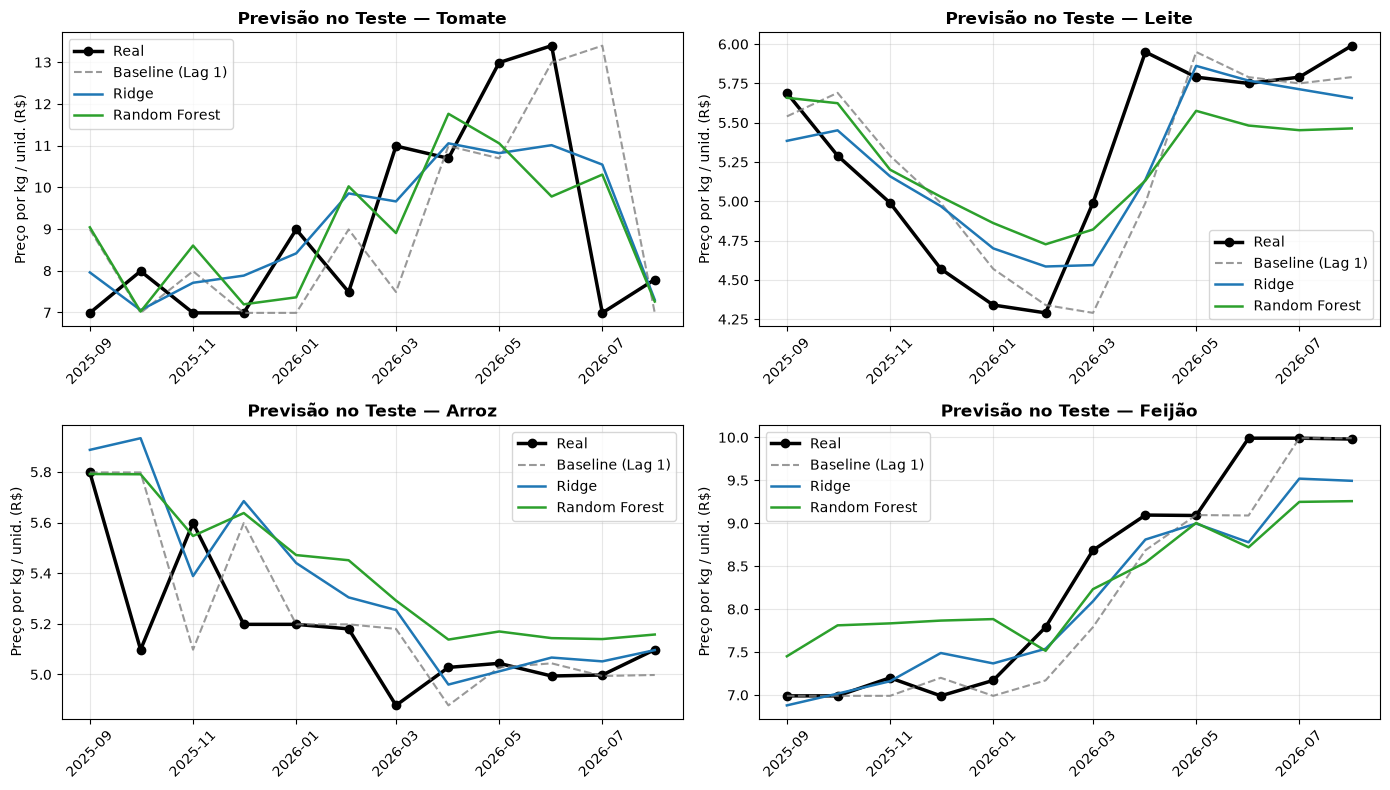

In [49]:
produtos_foco = ['Tomate', 'Leite', 'Arroz', 'Feijão']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, prod in zip(axes, produtos_foco):
    sub = df_previsoes[df_previsoes['produto'] == prod]
    ax.plot(sub['mes'], sub['ppk_mediana'], label='Real', color='black', linewidth=2.5, marker='o')
    ax.plot(sub['mes'], sub['pred_baseline'], label='Baseline (Lag 1)', linestyle='--', color='gray', alpha=0.8)
    ax.plot(sub['mes'], sub['pred_ridge'], label='Ridge', linestyle='-', color='tab:blue', linewidth=1.8)
    ax.plot(sub['mes'], sub['pred_rf'], label='Random Forest', linestyle='-', color='tab:green', linewidth=1.8)
    
    ax.set_title(f'Previsão no Teste — {prod}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Preço por kg / unid. (R$)')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

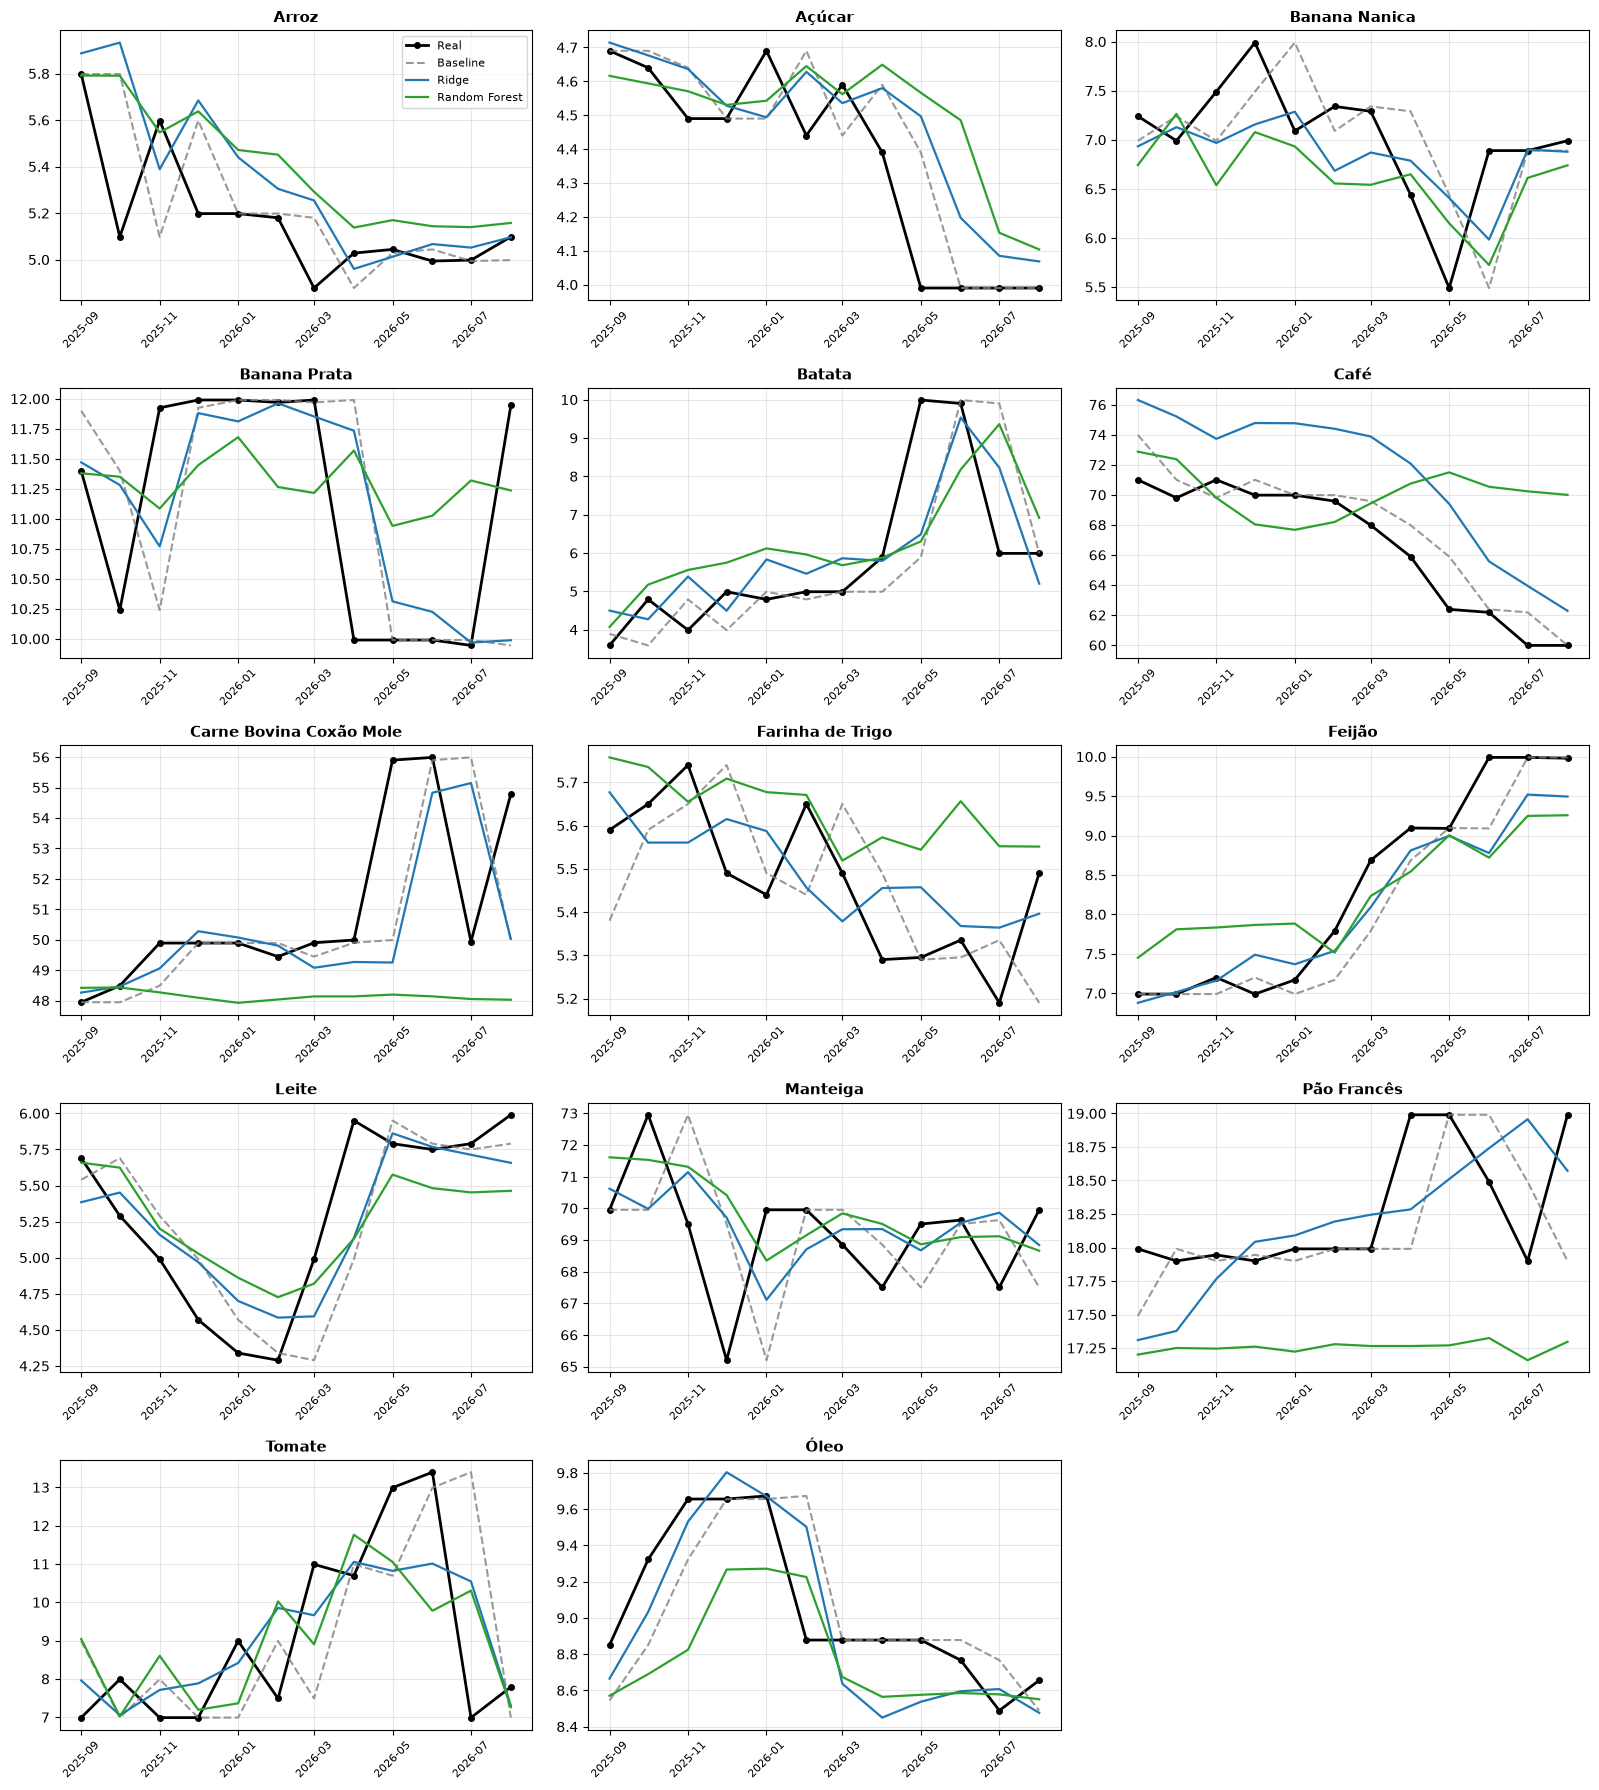

In [50]:
fig, axes = plt.subplots(5, 3, figsize=(16, 18))
axes = axes.flatten()

for i, prod in enumerate(produtos_elegiveis):
    ax = axes[i]
    sub = df_previsoes[df_previsoes['produto'] == prod]
    
    ax.plot(sub['mes'], sub['ppk_mediana'], label='Real', color='black', linewidth=2, marker='o', markersize=4)
    ax.plot(sub['mes'], sub['pred_baseline'], label='Baseline', linestyle='--', color='gray', alpha=0.8)
    ax.plot(sub['mes'], sub['pred_ridge'], label='Ridge', color='tab:blue', linewidth=1.6)
    ax.plot(sub['mes'], sub['pred_rf'], label='Random Forest', color='tab:green', linewidth=1.6)
    
    ax.set_title(prod, fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.grid(True, alpha=0.3)
    if i == 0:
        ax.legend(fontsize=8)

# Esconde o 15º gráfico (vazio)
axes[-1].axis('off')

plt.tight_layout()
plt.show()

In [51]:
import warnings
from statsmodels.tsa.holtwinters import ExponentialSmoothing

previsoes_hw = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    for prod in produtos_elegiveis:
        # Pega a série completa do produto (48 meses) ordenada por data
        serie_prod = df[df['produto'] == prod].sort_values('mes').reset_index(drop=True)
        
        # Datas do período de teste (>= data_corte)
        datas_teste = serie_prod[serie_prod['mes'] >= data_corte]['mes']
        
        for data_alvo in datas_teste:
            # Histórico disponível estritamente ANTES do mês que queremos prever
            hist = serie_prod[serie_prod['mes'] < data_alvo]['ppk_mediana'].values
            
            # Treina o Holt-Winters e prevê 1 mês à frente
            modelo_hw = ExponentialSmoothing(
                hist,
                trend='add',
                damped_trend=True,
                seasonal='mul',
                seasonal_periods=12
            ).fit(optimized=True)
            
            pred = modelo_hw.forecast(1)[0]
            previsoes_hw.append({'mes': data_alvo, 'produto': prod, 'pred_hw': pred})

df_hw = pd.DataFrame(previsoes_hw)

# Junta a previsão do Holt-Winters na nossa tabela principal (removendo se já existir antes)
if 'pred_hw' in df_previsoes.columns:
    df_previsoes = df_previsoes.drop(columns=['pred_hw'])

df_previsoes = df_previsoes.merge(df_hw, on=['mes', 'produto'], how='left')
display(df_previsoes.head(10))

,mes,produto,ppk_mediana,pred_baseline,pred_ridge,pred_rf,pred_hw
0,2025-09-01,Arroz,5.798,5.798,5.886993,5.791631,5.776641
1,2025-10-01,Arroz,5.098,5.798,5.933102,5.790634,5.815644
2,2025-11-01,Arroz,5.598,5.098,5.388539,5.546936,5.275409
3,2025-12-01,Arroz,5.198,5.598,5.684690,5.637590,5.389430
4,2026-01-01,Arroz,5.198,5.198,5.440178,5.471530,5.255701
5,2026-02-01,Arroz,5.180,5.198,5.304456,5.451142,5.166632
6,2026-03-01,Arroz,4.878,5.180,5.254578,5.291910,4.920777
7,2026-04-01,Arroz,5.028,4.878,4.960168,5.137810,4.639062
8,2026-05-01,Arroz,5.044,5.028,5.012318,5.169829,4.797153
9,2026-06-01,Arroz,4.994,5.044,5.066854,5.143606,4.903262


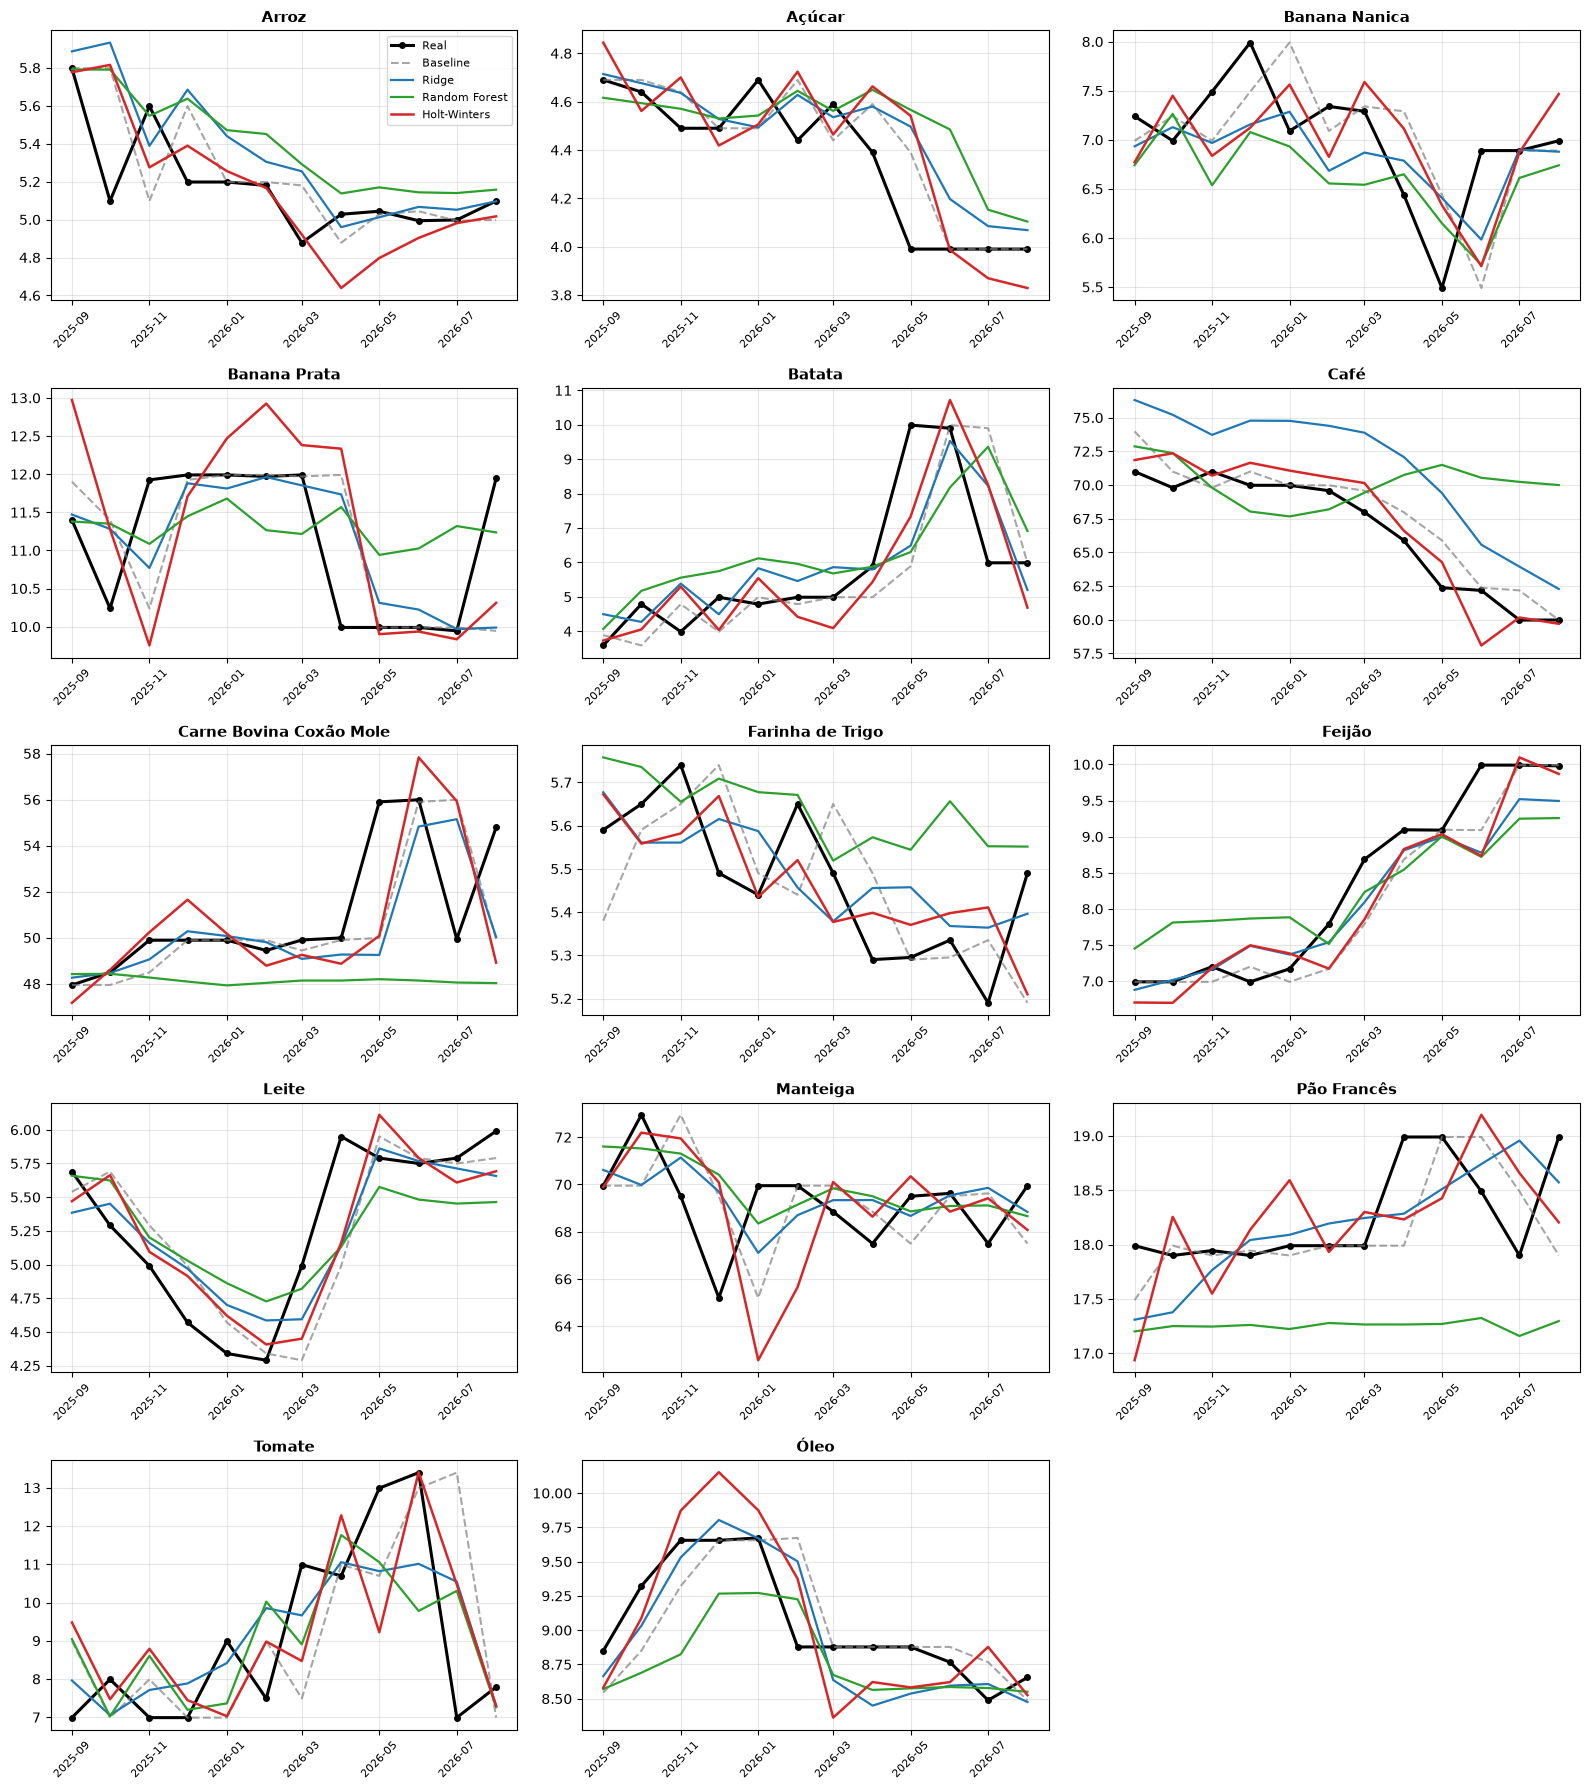

In [52]:
fig, axes = plt.subplots(5, 3, figsize=(16, 18))
axes = axes.flatten()

for i, prod in enumerate(produtos_elegiveis):
    ax = axes[i]
    sub = df_previsoes[df_previsoes['produto'] == prod]
    
    ax.plot(sub['mes'], sub['ppk_mediana'], label='Real', color='black', linewidth=2.2, marker='o', markersize=4)
    ax.plot(sub['mes'], sub['pred_baseline'], label='Baseline', linestyle='--', color='gray', alpha=0.7)
    ax.plot(sub['mes'], sub['pred_ridge'], label='Ridge', color='tab:blue', linewidth=1.6)
    ax.plot(sub['mes'], sub['pred_rf'], label='Random Forest', color='tab:green', linewidth=1.6)
    ax.plot(sub['mes'], sub['pred_hw'], label='Holt-Winters', color='tab:red', linewidth=1.8)
    
    ax.set_title(prod, fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.grid(True, alpha=0.3)
    if i == 0:
        ax.legend(fontsize=8)

axes[-1].axis('off')

plt.tight_layout()
plt.show()

In [53]:
resultados_multi = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    for prod in produtos_elegiveis:
        tr = treino[treino['produto'] == prod].sort_values('mes')
        te = teste[teste['produto'] == prod].sort_values('mes').reset_index(drop=True)
        
        # Treina Ridge e Random Forest apenas no treino
        modelo_ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        modelo_ridge.fit(tr[features], tr[target])
        
        modelo_rf = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)
        modelo_rf.fit(tr[features], tr[target])
        
        # Treina Holt-Winters até a data de corte e prevê os 12 meses direto
        hist_completo = df[(df['produto'] == prod) & (df['mes'] < data_corte)].sort_values('mes')['ppk_mediana'].values
        modelo_hw = ExponentialSmoothing(
            hist_completo, trend='add', damped_trend=True, seasonal='mul', seasonal_periods=12
        ).fit(optimized=True)
        preds_hw = modelo_hw.forecast(len(te))
        
        # Previsão recursiva (usando a própria previsão como lag para o mês seguinte)
        hist_ridge = tr['ppk_mediana'].iloc[-3:].tolist()
        hist_rf    = tr['ppk_mediana'].iloc[-3:].tolist()
        
        preds_ridge, preds_rf = [], []
        
        for i in range(len(te)):
            m_sin = te.loc[i, 'mes_sin']
            m_cos = te.loc[i, 'mes_cos']
            
            # Passo recursivo do Ridge
            X_r = pd.DataFrame([[hist_ridge[-1], hist_ridge[-2], hist_ridge[-3], np.mean(hist_ridge[-3:]), m_sin, m_cos]], columns=features)
            p_r = modelo_ridge.predict(X_r)[0]
            preds_ridge.append(p_r)
            hist_ridge.append(p_r)
            
            # Passo recursivo da Random Forest
            X_f = pd.DataFrame([[hist_rf[-1], hist_rf[-2], hist_rf[-3], np.mean(hist_rf[-3:]), m_sin, m_cos]], columns=features)
            p_f = modelo_rf.predict(X_f)[0]
            preds_rf.append(p_f)
            hist_rf.append(p_f)
            
        te_res = te[['mes', 'produto', 'ppk_mediana']].copy()
        te_res['pred_baseline'] = tr['ppk_mediana'].iloc[-1]  # Baseline fixo no último mês real conhecido
        te_res['pred_ridge'] = preds_ridge
        te_res['pred_rf'] = preds_rf
        te_res['pred_hw'] = preds_hw
        resultados_multi.append(te_res)

df_multi = pd.concat(resultados_multi, ignore_index=True)
display(df_multi.head(10))


,mes,produto,ppk_mediana,pred_baseline,pred_ridge,pred_rf,pred_hw
0,2025-09-01,Arroz,5.798,5.798,5.886993,5.791631,5.776641
1,2025-10-01,Arroz,5.098,5.798,6.005461,5.790634,5.791450
2,2025-11-01,Arroz,5.598,5.798,6.139974,5.824435,5.838301
3,2025-12-01,Arroz,5.198,5.798,6.259476,5.848698,5.850473
4,2026-01-01,Arroz,5.198,5.798,6.340585,5.879229,5.945691
5,2026-02-01,Arroz,5.180,5.798,6.368434,5.961150,6.028985
6,2026-03-01,Arroz,4.878,5.798,6.342216,6.133057,5.875056
7,2026-04-01,Arroz,5.028,5.798,6.274982,6.138664,5.715471
8,2026-05-01,Arroz,5.044,5.798,6.190318,6.097095,5.693210
9,2026-06-01,Arroz,4.994,5.798,6.116029,6.004987,5.605217


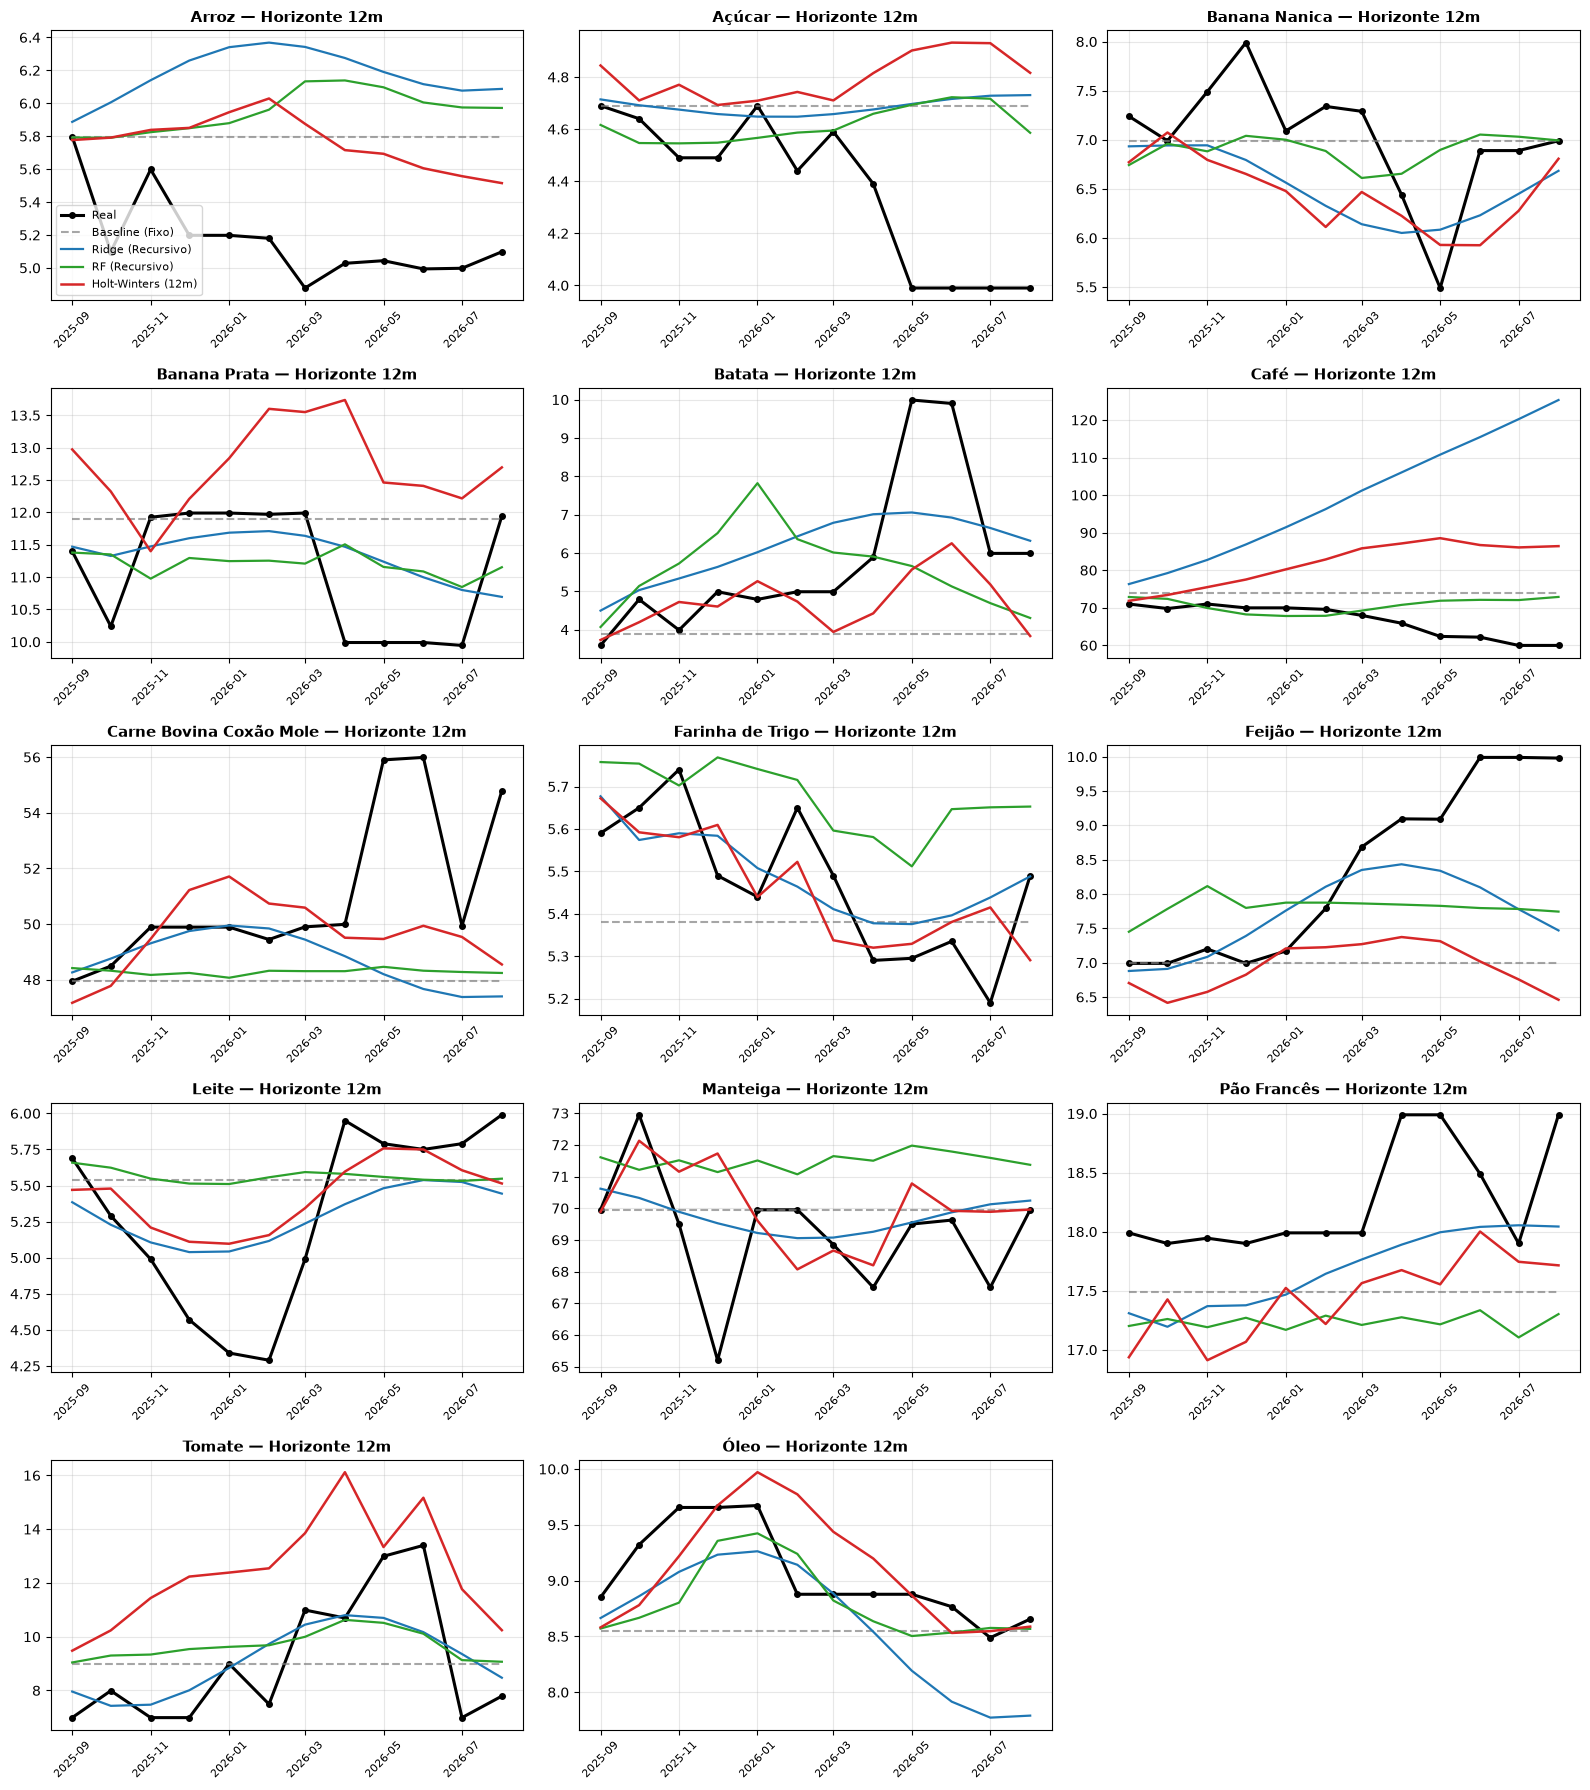

In [54]:
fig, axes = plt.subplots(5, 3, figsize=(16, 18))
axes = axes.flatten()

for i, prod in enumerate(produtos_elegiveis):
    ax = axes[i]
    sub = df_multi[df_multi['produto'] == prod]
    
    ax.plot(sub['mes'], sub['ppk_mediana'], label='Real', color='black', linewidth=2.2, marker='o', markersize=4)
    ax.plot(sub['mes'], sub['pred_baseline'], label='Baseline (Fixo)', linestyle='--', color='gray', alpha=0.7)
    ax.plot(sub['mes'], sub['pred_ridge'], label='Ridge (Recursivo)', color='tab:blue', linewidth=1.6)
    ax.plot(sub['mes'], sub['pred_rf'], label='RF (Recursivo)', color='tab:green', linewidth=1.6)
    ax.plot(sub['mes'], sub['pred_hw'], label='Holt-Winters (12m)', color='tab:red', linewidth=1.8)
    
    ax.set_title(f"{prod} — Horizonte 12m", fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.grid(True, alpha=0.3)
    if i == 0:
        ax.legend(fontsize=8)

axes[-1].axis('off')

plt.tight_layout()
plt.show()

In [55]:
horizonte = 6
ultima_data = df['mes'].max()
datas_futuras = pd.date_range(start=ultima_data + pd.DateOffset(months=1), periods=horizonte, freq='MS')

previsoes_futuras = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    for prod in produtos_elegiveis:
        # Base completa do produto para treino final
        tr_full = df_modelo[df_modelo['produto'] == prod].sort_values('mes')
        serie_full = df[df['produto'] == prod].sort_values('mes')['ppk_mediana'].values
        
        # Treina Ridge e Random Forest com todos os dados
        modelo_ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        modelo_ridge.fit(tr_full[features], tr_full[target])
        
        modelo_rf = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)
        modelo_rf.fit(tr_full[features], tr_full[target])
        
        # Treina Holt-Winters com todos os 48 meses e prevê os próximos 6
        modelo_hw = ExponentialSmoothing(
            serie_full, trend='add', damped_trend=True, seasonal='mul', seasonal_periods=12
        ).fit(optimized=True)
        preds_hw = modelo_hw.forecast(horizonte)
        
        # Inicializa histórico com os últimos 3 preços reais (jun, jul, ago/2026)
        hist_ridge = serie_full[-3:].tolist()
        hist_rf    = serie_full[-3:].tolist()
        
        for i, data_fut in enumerate(datas_futuras):
            m_num = data_fut.month
            m_sin = np.sin(2 * np.pi * (m_num - 1) / 12)
            m_cos = np.cos(2 * np.pi * (m_num - 1) / 12)
            
            # Ridge recursivo
            X_r = pd.DataFrame([[hist_ridge[-1], hist_ridge[-2], hist_ridge[-3], np.mean(hist_ridge[-3:]), m_sin, m_cos]], columns=features)
            p_r = modelo_ridge.predict(X_r)[0]
            hist_ridge.append(p_r)
            
            # Random Forest recursivo
            X_f = pd.DataFrame([[hist_rf[-1], hist_rf[-2], hist_rf[-3], np.mean(hist_rf[-3:]), m_sin, m_cos]], columns=features)
            p_f = modelo_rf.predict(X_f)[0]
            hist_rf.append(p_f)
            
            previsoes_futuras.append({
                'mes': data_fut,
                'produto': prod,
                'pred_ridge': p_r,
                'pred_rf': p_f,
                'pred_hw': preds_hw[i]
            })

df_futuro = pd.DataFrame(previsoes_futuras)
display(df_futuro.head(12))


,mes,produto,pred_ridge,pred_rf,pred_hw
0,2026-09-01,Arroz,5.151939,5.274984,5.141992
1,2026-10-01,Arroz,5.249226,5.319082,5.088816
2,2026-11-01,Arroz,5.340740,5.485154,5.315422
3,2026-12-01,Arroz,5.430616,5.507726,5.316093
4,2027-01-01,Arroz,5.496553,5.493478,5.455210
5,2027-02-01,Arroz,5.533856,5.491189,5.579023
6,2026-09-01,Açúcar,4.044765,4.207457,4.048517
7,2026-10-01,Açúcar,4.090920,4.319023,3.971478
8,2026-11-01,Açúcar,4.137303,4.352572,3.983011
9,2026-12-01,Açúcar,4.176961,4.213402,3.942054


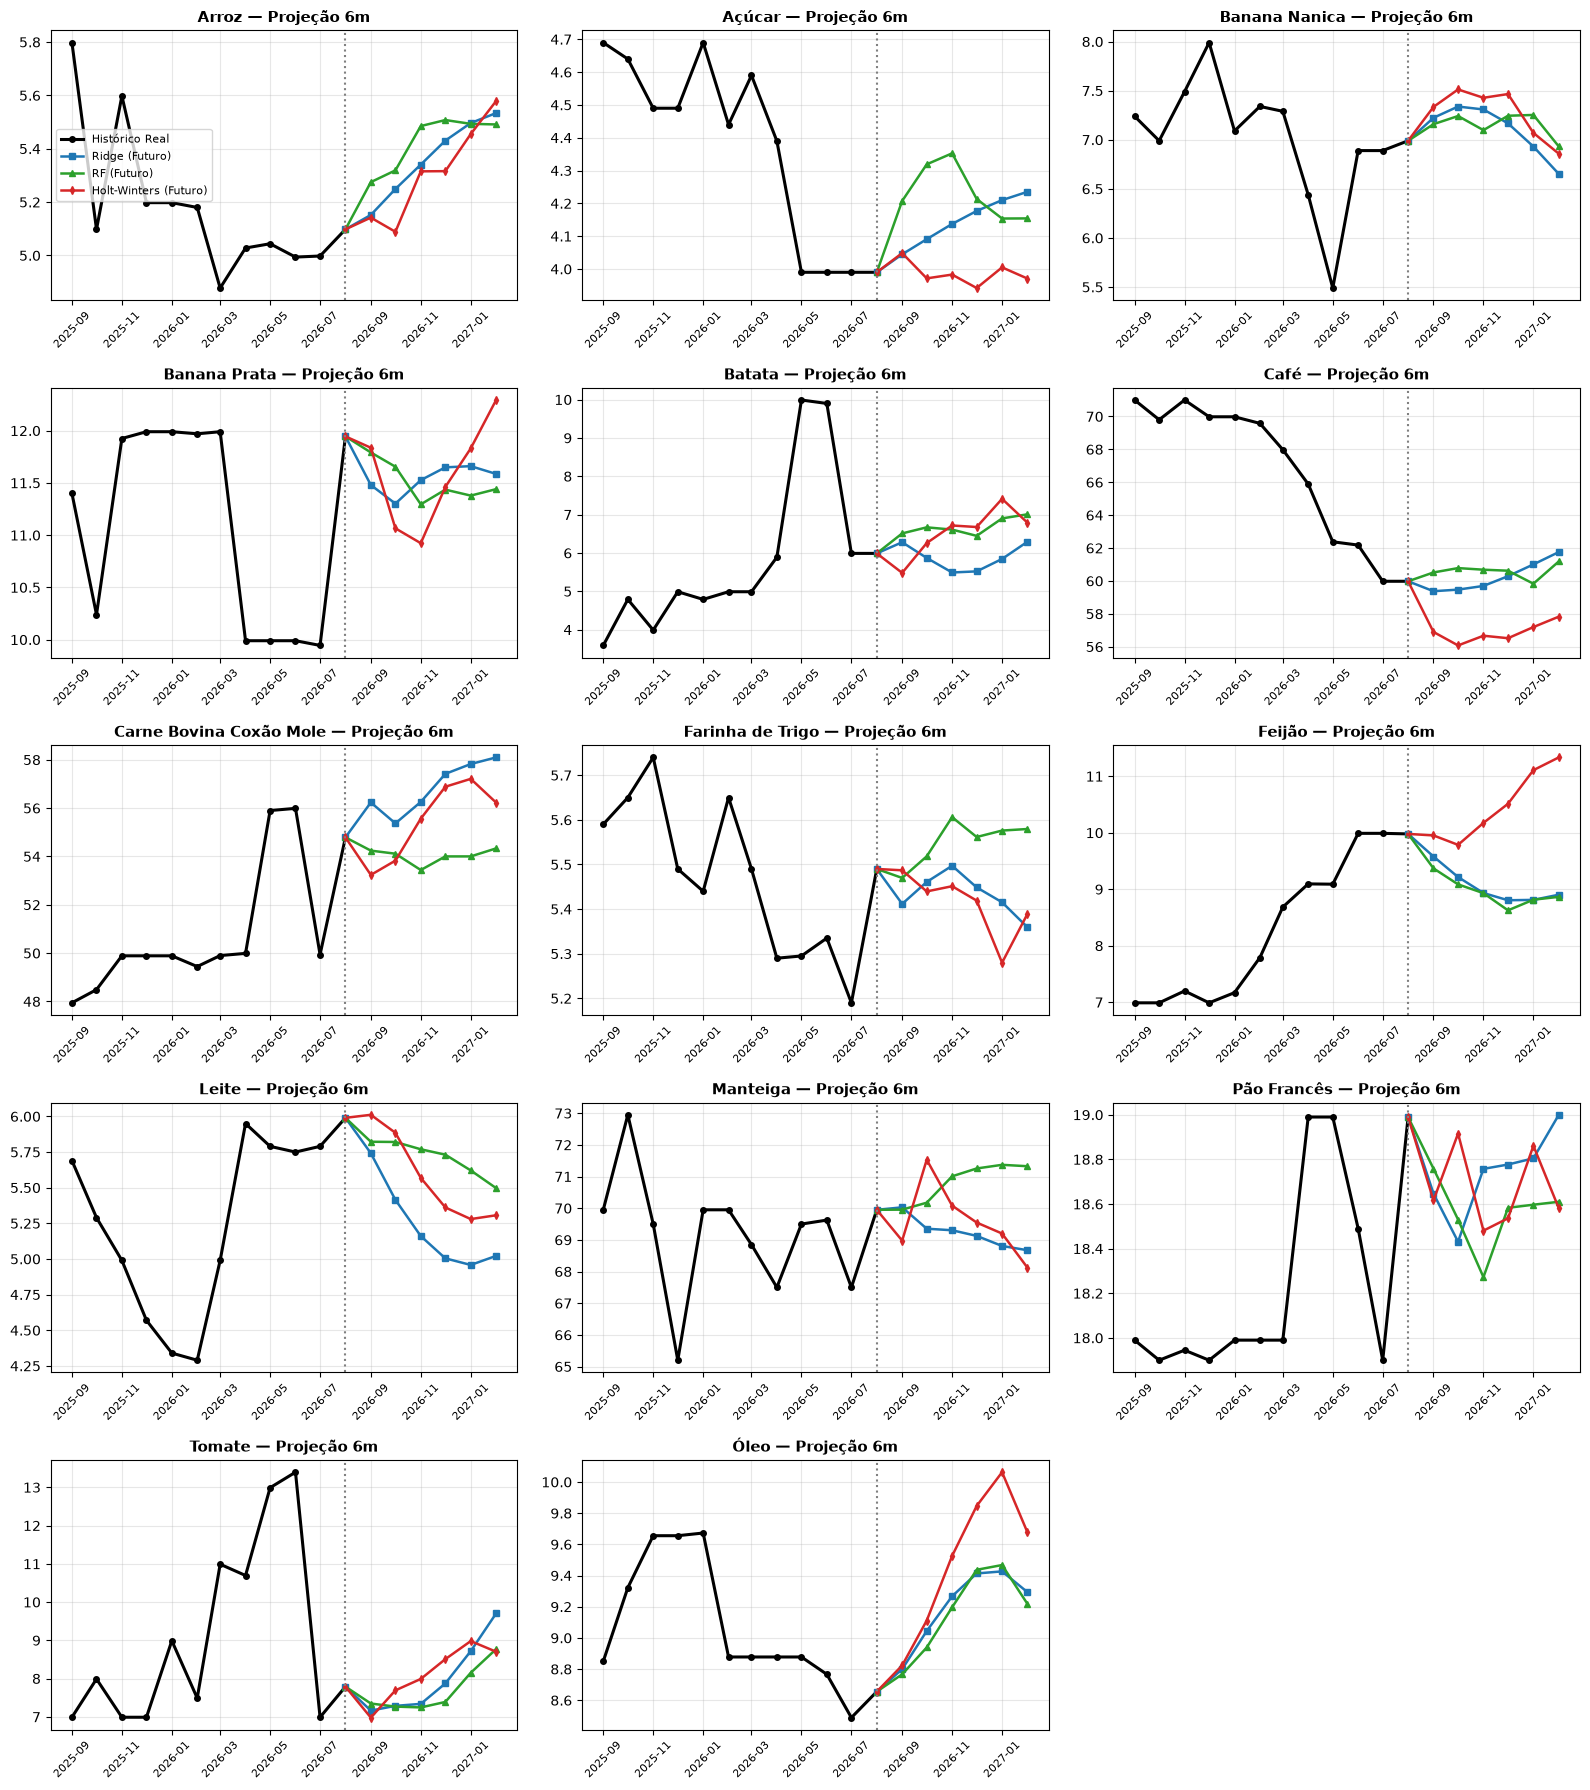

In [56]:
fig, axes = plt.subplots(5, 3, figsize=(16, 18))
axes = axes.flatten()

for i, prod in enumerate(produtos_elegiveis):
    ax = axes[i]
    
    # Últimos 12 meses reais
    hist_rec = df[df['produto'] == prod].sort_values('mes').tail(12)
    fut = df_futuro[df_futuro['produto'] == prod]
    
    # Último ponto real (agosto/2026) para conectar visualmente as linhas
    ultimo_mes = hist_rec['mes'].iloc[-1]
    ultimo_val = hist_rec['ppk_mediana'].iloc[-1]
    
    meses_fut = pd.concat([pd.Series([ultimo_mes]), fut['mes']])
    ridge_plot = pd.concat([pd.Series([ultimo_val]), fut['pred_ridge']])
    rf_plot    = pd.concat([pd.Series([ultimo_val]), fut['pred_rf']])
    hw_plot    = pd.concat([pd.Series([ultimo_val]), fut['pred_hw']])
    
    ax.plot(hist_rec['mes'], hist_rec['ppk_mediana'], label='Histórico Real', color='black', linewidth=2.2, marker='o', markersize=4)
    ax.plot(meses_fut, ridge_plot, label='Ridge (Futuro)', color='tab:blue', linewidth=1.8, marker='s', markersize=4)
    ax.plot(meses_fut, rf_plot, label='RF (Futuro)', color='tab:green', linewidth=1.8, marker='^', markersize=4)
    ax.plot(meses_fut, hw_plot, label='Holt-Winters (Futuro)', color='tab:red', linewidth=1.8, marker='d', markersize=4)
    
    ax.axvline(ultima_data, color='gray', linestyle=':', linewidth=1.5)
    ax.set_title(f"{prod} — Projeção 6m", fontsize=11, fontweight='bold')
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.grid(True, alpha=0.3)
    if i == 0:
        ax.legend(fontsize=8)

axes[-1].axis('off')
plt.tight_layout()
plt.savefig('../reports/figures/previsao_futura_14_produtos.png', dpi=150, bbox_inches='tight')
plt.show()

In [57]:
df_previsoes.to_csv('../data/processed/previsoes_teste_1passo.csv', index=False)
df_multi.to_csv('../data/processed/previsoes_teste_multipassos.csv', index=False)
df_futuro.to_csv('../data/processed/previsoes_futuras.csv', index=False)

print("Arquivos exportados com sucesso para data/processed/!")

Arquivos exportados com sucesso para data/processed/!
